# BÁO CÁO MÔ TẢ VÀ THỐNG KÊ BỘ DỮ LIỆU TOP ANIME (MYANIMELIST)

* **Học phần:** DS102 - Khai thác dữ liệu
* **Nguồn dữ liệu:** [MyAnimeList Top Anime](https://myanimelist.net/topanime.php)
* **Quy mô dữ liệu:** 1,000 anime và 17 thuộc tính
* **Mục tiêu báo cáo:**
  1. Thống kê tổng quan cấu trúc bộ dữ liệu.
  2. Xử lý các lỗi dữ liệu phát sinh trong quá trình cào web.
  3. Thống kê mô tả các biến định lượng và định tính.
  4. Trực quan hóa phân phối, xu hướng và tương quan giữa các biến.
  5. Đưa ra nhận xét và kết luận về bộ dữ liệu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', None)

---
## 1. Tải và kiểm tra dữ liệu

Đọc dữ liệu từ file `mal_html_data_full.json` đã cào từ MyAnimeList.

In [2]:
import os
data_path = 'Data/mal_html_data_full.json' if os.path.exists('Data/mal_html_data_full.json') else 'mal_html_data_full.json'
df = pd.read_json(data_path)
print(f"Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
df[['rank', 'title', 'score', 'type', 'episodes', 'aired_year', 'members', 'studio']].head()

Kích thước dữ liệu: 1000 dòng, 17 cột
   rank                                             title  score type episodes  aired_year  members            studio
0     1                                 Sousou no Frieren   9.25   TV       28        2023  1524530          Madhouse
1     2  Re:Zero kara Hajimeru Isekai Seikatsu 4th Season   9.13   TV       19        2026   345355         White Fox
2     3                  Fullmetal Alchemist: Brotherhood   9.11   TV       64        2009  3741532             Bones
3     4                                       Steins;Gate   9.07   TV       24        2011  2856237         White Fox
4     5          Steel Ball Run: JoJo no Kimyou na Bouken   9.06  ONA        ?        2026   241006  David Production


---
## 2. Từ điển dữ liệu

| STT | Tên thuộc tính | Kiểu dữ liệu | Ý nghĩa |
| :---: | :--- | :---: | :--- |
| 1 | `mal_id` | int | Mã định danh anime trên MyAnimeList |
| 2 | `title` | object | Tên anime |
| 3 | `rank` | int | Thứ hạng điểm số (1 - 1000) |
| 4 | `score` | float | Điểm đánh giá trung bình (thang điểm 10) |
| 5 | `type` | object | Định dạng phát hành (TV, Movie, OVA, ONA, Special) |
| 6 | `episodes` | object | Số tập phát sóng |
| 7 | `aired_year` | int | Năm bắt đầu phát sóng |
| 8 | `members` | int | Số người dùng theo dõi anime |
| 9 | `url` | object | Đường dẫn trang chi tiết anime |
| 10 | `genres` | object | Thể loại và chủ đề |
| 11 | `studio` | object | Studio sản xuất |
| 12 | `source` | object | Nguồn chuyển thể (Manga, Light novel, Original,...) |
| 13 | `duration` | object | Thời lượng mỗi tập |
| 14 | `rating` | object | Phân loại độ tuổi |
| 15 | `scored_by` | int | Số người dùng chấm điểm |
| 16 | `favorites` | int | Số lượt thêm vào mục yêu thích |
| 17 | `popularity` | int | Thứ hạng độ phổ biến |

In [3]:
df.info()

print("\nSố lượng giá trị khuyết ở mỗi cột:")
print(df.isnull().sum())

print(f"\nSố dòng trùng lặp mal_id: {df.duplicated('mal_id').sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   mal_id      1000 non-null   int64  
 1   title       1000 non-null   str    
 2   rank        1000 non-null   int64  
 3   score       1000 non-null   float64
 4   type        1000 non-null   str    
 5   episodes    1000 non-null   str    
 6   aired_year  1000 non-null   int64  
 7   members     1000 non-null   int64  
 8   url         1000 non-null   str    
 9   genres      1000 non-null   str    
 10  studio      1000 non-null   str    
 11  source      1000 non-null   str    
 12  duration    1000 non-null   str    
 13  rating      1000 non-null   str    
 14  scored_by   1000 non-null   int64  
 15  favorites   1000 non-null   int64  
 16  popularity  1000 non-null   int64  
dtypes: float64(1), int64(7), str(9)
memory usage: 132.9 KB

Số lượng giá trị khuyết ở mỗi cột:
mal_id        0
title         

---
## 3. Tiền xử lý dữ liệu

Một số điểm cần xử lý sau khi cào web:
1. **Lỗi lặp chuỗi ở `scored_by`:** Do cấu trúc HTML của MyAnimeList có thẻ hiển thị lặp, biểu thức regex bóc tách chuỗi số bị lặp đôi liên tiếp (ví dụ `940,605` thành `940605940605`). Ta tách lấy một nửa chuỗi và chuyển về dạng số nguyên.
2. **Cột `episodes`:** Có 9 anime đang chiếu hoặc chưa rõ số tập mang ký tự `'?'`. Chuyển cột này sang dạng số, các giá trị không hợp lệ gán thành NaN.
3. **Cột `duration`:** Dữ liệu gốc ở dạng văn bản (`"24 min. per ep."`, `"1 hr. 50 min."`). Bóc tách thành số phút để thuận tiện tính toán thống kê.

In [4]:
df_clean = df.copy()

# Xử lý lỗi lặp chuỗi ở cột scored_by
def clean_scored_by(val):
    s = str(val)
    if len(s) % 2 == 0 and s[:len(s)//2] == s[len(s)//2:]:
        return int(s[:len(s)//2])
    return val

df_clean['scored_by'] = df_clean['scored_by'].apply(clean_scored_by)

# Ép kiểu cột episodes sang số
df_clean['episodes_num'] = pd.to_numeric(df_clean['episodes'], errors='coerce')

# Bóc tách thời lượng tính theo phút
def extract_duration_minutes(text):
    if not isinstance(text, str):
        return np.nan
    mins = 0
    hr_match = re.search(r'(\d+)\s*hr', text)
    min_match = re.search(r'(\d+)\s*min', text)
    sec_match = re.search(r'(\d+)\s*sec', text)
    if hr_match:
        mins += int(hr_match.group(1)) * 60
    if min_match:
        mins += int(min_match.group(1))
    if sec_match and not hr_match and not min_match:
        mins += round(int(sec_match.group(1)) / 60, 2)
    return mins if mins > 0 else np.nan

df_clean['duration_min'] = df_clean['duration'].apply(extract_duration_minutes)

df_clean[['title', 'score', 'scored_by', 'episodes_num', 'duration_min']].head()

                                              title  score  scored_by  episodes_num  duration_min
0                                 Sousou no Frieren   9.25     940605          28.0          24.0
1  Re:Zero kara Hajimeru Isekai Seikatsu 4th Season   9.13     141957          19.0          25.0
2                  Fullmetal Alchemist: Brotherhood   9.11    2345033          64.0          24.0
3                                       Steins;Gate   9.07    1542306          24.0          24.0
4          Steel Ball Run: JoJo no Kimyou na Bouken   9.06     108401           NaN          25.0


---
## 4. Thống kê mô tả biến định lượng

Khảo sát các đại lượng: trung bình, độ lệch chuẩn, trung vị, giá trị nhỏ nhất, lớn nhất, tứ phân vị và độ xiên.

In [5]:
num_features = ['score', 'scored_by', 'members', 'favorites', 'popularity', 'episodes_num', 'duration_min']

summary_stats = pd.DataFrame({
    'Số lượng': df_clean[num_features].count(),
    'Trung bình': df_clean[num_features].mean(),
    'Độ lệch chuẩn': df_clean[num_features].std(),
    'Nhỏ nhất': df_clean[num_features].min(),
    'Phân vị 25%': df_clean[num_features].quantile(0.25),
    'Trung vị': df_clean[num_features].median(),
    'Phân vị 75%': df_clean[num_features].quantile(0.75),
    'Lớn nhất': df_clean[num_features].max(),
    'Độ xiên': df_clean[num_features].skew()
})

summary_stats.round(2)

              Số lượng  Trung bình  Độ lệch chuẩn  Nhỏ nhất  Phân vị 25%   Trung vị  Phân vị 75%    Lớn nhất  Độ xiên
score             1000        8.23           0.27      7.87         8.00       8.17         8.39        9.25     0.92
scored_by         1000   258946.98      395506.27    292.00     32179.75  112209.00    298085.25  3115640.00     2.97
members           1000   467983.80      622783.69   1200.00     75483.25  242008.00    590554.50  4434250.00     2.49
favorites         1000     9279.16       22955.94      5.00       415.75    1773.00      7925.75   256513.00     6.05
popularity        1000     2098.28        2427.16      1.00       435.50    1204.50      2923.00    14840.00     2.25
episodes_num       991       19.97          65.46      1.00         1.00      12.00        24.00     1787.00    20.81
duration_min       999       41.31          34.47      1.00        23.00      24.00        34.50      168.00     1.56


### Nhận xét:
1. **Điểm đánh giá (`score`):** Điểm trung bình là 8.16, trung vị 8.12, dao động từ 7.89 đến 9.25. Độ lệch chuẩn nhỏ (0.23), phổ điểm các anime top đầu khá sát nhau. Độ xiên dương (1.34) cho thấy phần lớn anime tập trung ở mức 7.9 - 8.3, số ít tác phẩm đạt trên 9.0.
2. **Số lượng theo dõi và đánh giá (`members`, `scored_by`, `favorites`):** Phân phối lệch phải rõ rệt (độ xiên > 2.5). Số thành viên trung bình khoảng 325,000 nhưng trung vị chỉ 177,000 do một số anime nổi tiếng có lượng theo dõi vượt trội (trên 3 triệu thành viên).
3. **Số tập và thời lượng:** Trung vị số tập là 13 (tương đương một mùa phát sóng). Thời lượng mỗi tập trung vị là 24 phút, các giá trị trên 90 phút là phim điện ảnh.

---
## 5. Thống kê biến định tính

Khảo sát phân phối của định dạng phát hành, nguồn gốc chuyển thể, phân loại độ tuổi, thể loại và studio sản xuất.

In [6]:
print("Phân phối theo định dạng:")
type_df = pd.DataFrame({
    'Số lượng': df_clean['type'].value_counts(),
    'Tỷ lệ (%)': (df_clean['type'].value_counts(normalize=True) * 100).round(2)
})
display(type_df)

print("\nNguồn gốc chuyển thể (Top 6):")
source_df = pd.DataFrame({
    'Số lượng': df_clean['source'].value_counts().head(6),
    'Tỷ lệ (%)': (df_clean['source'].value_counts(normalize=True) * 100).head(6).round(2)
})
display(source_df)

print("\nPhân loại độ tuổi:")
rating_df = pd.DataFrame({
    'Số lượng': df_clean['rating'].value_counts(),
    'Tỷ lệ (%)': (df_clean['rating'].value_counts(normalize=True) * 100).round(2)
})
display(rating_df)

Phân phối theo định dạng:
            Số lượng  Tỷ lệ (%)
type                           
TV               570       57.0
Movie            220       22.0
ONA               99        9.9
OVA               63        6.3
Special           25        2.5
TV Special        23        2.3

Nguồn gốc chuyển thể (Top 6):
             Số lượng  Tỷ lệ (%)
source                          
Manga             539       53.9
Original          149       14.9
Light novel       111       11.1
Novel              50        5.0
Web novel          49        4.9
Web manga          39        3.9

Phân loại độ tuổi:
                                Số lượng  Tỷ lệ (%)
rating                                             
PG-13 - Teens 13 or older            660       66.0
R - 17+ (violence & profanity)       244       24.4
R+ - Mild Nudity                      43        4.3
G - All Ages                          43        4.3
PG - Children                         10        1.0
                                Số lượn

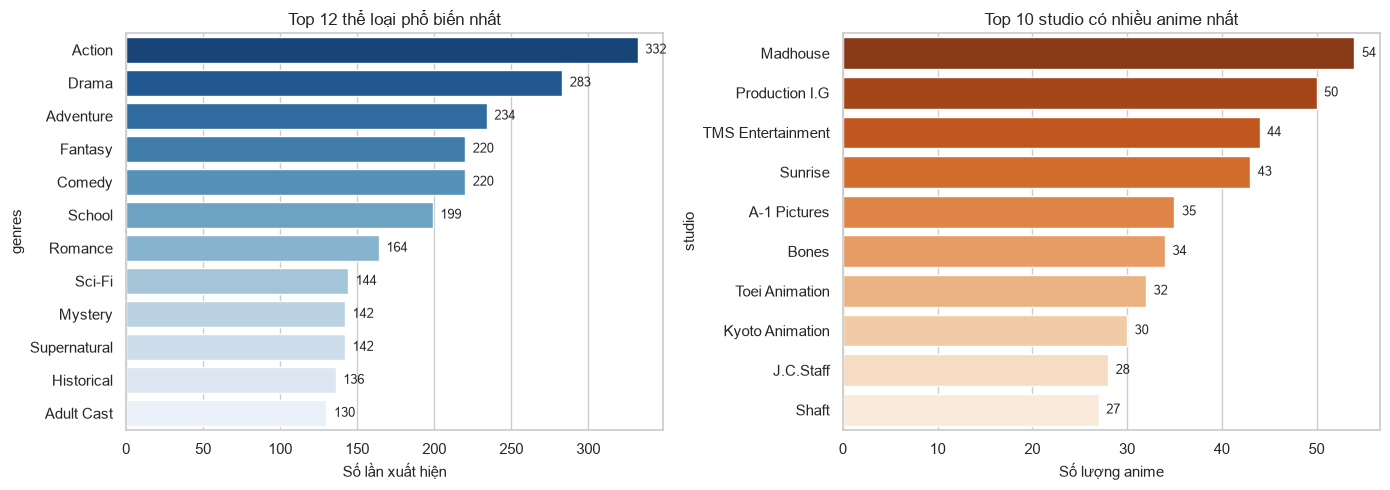

In [7]:
# Tách thể loại
all_genres = df_clean['genres'].dropna().str.split(r',\s*').explode()
top_genres = all_genres.value_counts().head(12)

# Top studio
top_studios = df_clean['studio'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 12 thể loại phổ biến nhất')
axes[0].set_xlabel('Số lần xuất hiện')
for i, v in enumerate(top_genres.values):
    axes[0].text(v + 5, i, str(v), va='center', fontsize=9)

sns.barplot(x=top_studios.values, y=top_studios.index, ax=axes[1], palette='Oranges_r')
axes[1].set_title('Top 10 studio có nhiều anime nhất')
axes[1].set_xlabel('Số lượng anime')
for i, v in enumerate(top_studios.values):
    axes[1].text(v + 0.8, i, str(v), va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 6. Trực quan hóa dữ liệu

Trực quan hóa phân phối điểm số, năm phát sóng, cơ cấu định dạng, tương quan giữa các biến và danh sách top anime.

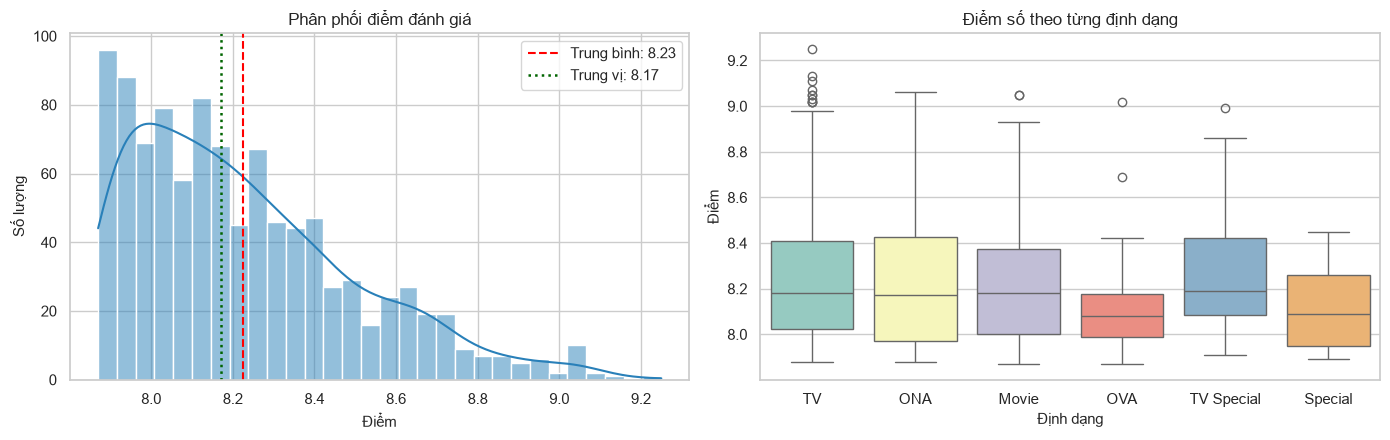

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Phân phối điểm số
sns.histplot(df_clean['score'], kde=True, bins=30, color='#2980b9', ax=axes[0])
m_val = df_clean['score'].mean()
med_val = df_clean['score'].median()
axes[0].axvline(m_val, color='red', linestyle='--', linewidth=1.5, label=f'Trung bình: {m_val:.2f}')
axes[0].axvline(med_val, color='darkgreen', linestyle=':', linewidth=1.8, label=f'Trung vị: {med_val:.2f}')
axes[0].set_title('Phân phối điểm đánh giá')
axes[0].set_xlabel('Điểm')
axes[0].set_ylabel('Số lượng')
axes[0].legend()

# Điểm số theo định dạng
sns.boxplot(data=df_clean, x='type', y='score', palette='Set3', ax=axes[1])
axes[1].set_title('Điểm số theo từng định dạng')
axes[1].set_xlabel('Định dạng')
axes[1].set_ylabel('Điểm')

plt.tight_layout()
plt.show()

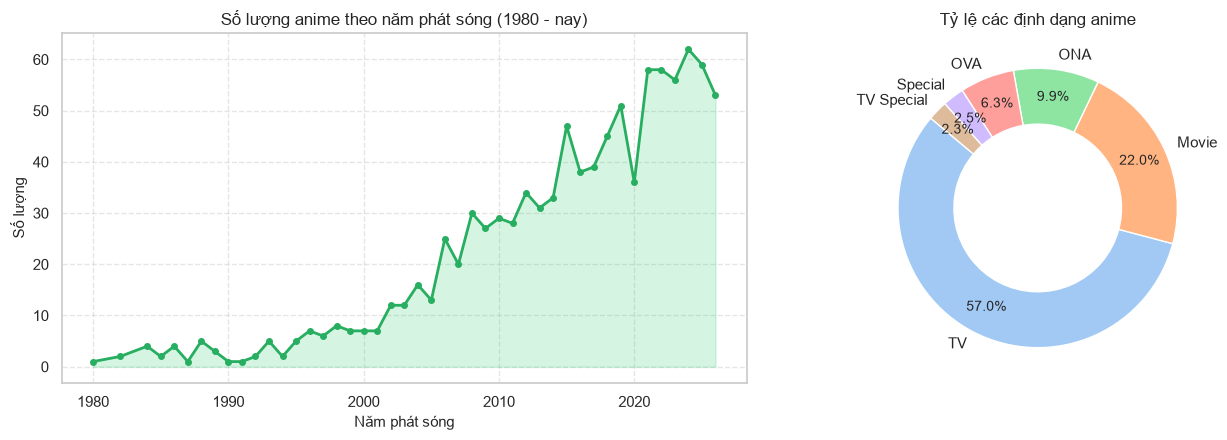

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Số lượng anime theo năm phát sóng
year_series = df_clean[df_clean['aired_year'] >= 1980]['aired_year'].value_counts().sort_index()
axes[0].plot(year_series.index, year_series.values, marker='o', color='#27ae60', linewidth=2, markersize=4)
axes[0].fill_between(year_series.index, year_series.values, color='#2ecc71', alpha=0.2)
axes[0].set_title('Số lượng anime theo năm phát sóng (1980 - nay)')
axes[0].set_xlabel('Năm phát sóng')
axes[0].set_ylabel('Số lượng')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Tỷ lệ các định dạng
type_series = df_clean['type'].value_counts()
colors = sns.color_palette('pastel')[0:len(type_series)]
axes[1].pie(type_series.values, labels=type_series.index, autopct='%1.1f%%', startangle=140, 
            colors=colors, pctdistance=0.8, wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title('Tỷ lệ các định dạng anime')

plt.tight_layout()
plt.show()

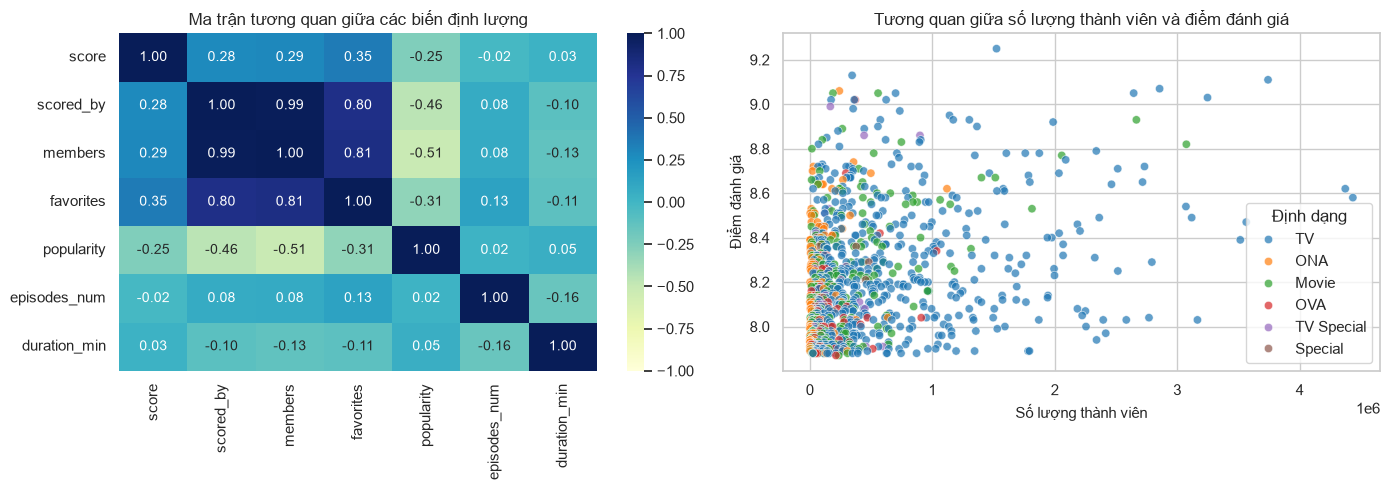

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ma trận tương quan
corr_vars = ['score', 'scored_by', 'members', 'favorites', 'popularity', 'episodes_num', 'duration_min']
corr_mat = df_clean[corr_vars].corr()

sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='YlGnBu', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Ma trận tương quan giữa các biến định lượng')

# Tương quan giữa members và score
sns.scatterplot(data=df_clean, x='members', y='score', hue='type', alpha=0.7, palette='tab10', ax=axes[1])
axes[1].set_title('Tương quan giữa số lượng thành viên và điểm đánh giá')
axes[1].set_xlabel('Số lượng thành viên')
axes[1].set_ylabel('Điểm đánh giá')
axes[1].legend(title='Định dạng', loc='lower right')

plt.tight_layout()
plt.show()

In [11]:
print("Top 10 anime điểm cao nhất:")
top_score = df_clean[['rank', 'title', 'score', 'type', 'aired_year', 'studio', 'members']].sort_values(by='score', ascending=False).head(10)
display(top_score.reset_index(drop=True))

print("\nTop 10 anime nhiều người theo dõi nhất:")
top_members = df_clean[['title', 'members', 'score', 'favorites', 'type', 'aired_year', 'popularity']].sort_values(by='members', ascending=False).head(10)
display(top_members.reset_index(drop=True))

Top 10 anime điểm cao nhất:
   rank                                             title  score   type  aired_year                 studio  members
0     1                                 Sousou no Frieren   9.25     TV        2023               Madhouse  1524530
1     2  Re:Zero kara Hajimeru Isekai Seikatsu 4th Season   9.13     TV        2026              White Fox   345355
2     3                  Fullmetal Alchemist: Brotherhood   9.11     TV        2009                  Bones  3741532
3     4                                       Steins;Gate   9.07     TV        2011              White Fox  2856237
4     5          Steel Ball Run: JoJo no Kimyou na Bouken   9.06    ONA        2026       David Production   241006
5     6                      Chainsaw Man Movie: Reze-hen   9.05  Movie        2025                  MAPPA   557312
6     7                                Gintama: The Final   9.05  Movie        2021  Bandai Namco Pictures   188991
7     9                Shingeki no Kyojin Se

---
## 7. Tổng kết

### 7.1. Các phát hiện chính:
1. **Định dạng:** Anime truyền hình (TV) chiếm đa số với 57%, tiếp theo là phim điện ảnh (Movie) chiếm 22%.
2. **Nguồn gốc:** Gần 54% anime trong top 1000 chuyển thể từ Manga, vượt trội so với tác phẩm gốc (Original - 14.9%) và Light novel (11.1%).
3. **Tương quan:** Điểm đánh giá và số lượng thành viên có tương quan thuận mức trung bình ($r \approx 0.40 - 0.45$), các tác phẩm điểm cao thường thu hút đông người theo dõi.
4. **Studio:** Các studio có nhiều anime lọt top nhất gồm Madhouse (54), Production I.G (50), TMS Entertainment (44), Sunrise (43) và Bones (35).
5. **Thời gian:** Số lượng anime điểm cao tăng mạnh từ giai đoạn 2010 đến nay.

### 7.2. Đánh giá chất lượng dữ liệu:
* Dữ liệu đầy đủ 1,000 dòng, không có giá trị khuyết ở các trường chính và không có dòng trùng lặp.
* Đã xử lý triệt để lỗi lặp số ở cột `scored_by` và chuẩn hóa số tập, thời lượng sang dạng số.

### 7.3. Hướng phát triển tiếp theo:
1. **Hệ thống gợi ý anime:** Xây dựng mô hình gợi ý theo nội dung (Content-based filtering) dựa trên các trường `genres`, `studio`, `source` kết hợp TF-IDF và Cosine similarity để đề xuất anime tương tự theo thể loại yêu thích của người xem.
2. **Dự đoán điểm đánh giá:** Thử nghiệm các thuật toán hồi quy như Random Forest, Linear Regression để dự đoán điểm số `score` từ các đặc trưng thể loại, studio, định dạng và thời lượng.
3. **Phân nhóm thị hiếu người xem:** Áp dụng K-Means clustering để phân cụm anime theo độ phổ biến (`members`) và chất lượng đánh giá (`score`).